# Buscador de suplementos herbales (DSLD)
### Escribe una palabra o un ingrediente y genera su dashboard

Este notebook complementa a `DSLD_herbal_analisis.ipynb`. Al buscar un término (por ejemplo `turmeric`, `ashwagandha`, `immune` o `alcohol free`) genera automáticamente un dashboard con **todas las etiquetas herbales** que lo contienen:

- Tamaño del grupo, marcas distintas y porcentaje en el mercado
- Formas de presentación y marcas que más lo usan
- Ingredientes con los que se combina
- Dosis declaradas (si es un ingrediente)
- Otras palabras que aparecen en sus títulos
- Una tabla con los productos, que además se guarda como CSV

**Qué cuenta como coincidencia.** Se busca la palabra completa en el **título** del producto y en los **nombres de ingredientes botánicos** (ya limpiados). Escribe en inglés, como están los datos del DSLD.

**Cómo ejecutarlo en Google Colab:** sube `DSLD-full-database-CSV.zip` a `MyDrive/dsld/` y ejecuta todas las celdas; al final aparece la caja de búsqueda.

## 1. Configuración

In [1]:
import glob
import difflib
import os
import re
import textwrap
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Rutas -------------------------------------------------------------------
# En Colab se monta Drive y se descomprime el zip. Para ejecutarlo en local,
# define las variables de entorno DSLD_DATA_DIR (carpeta con los CSV) y DSLD_OUT_DIR.
if "DSLD_DATA_DIR" in os.environ:
    DATA_DIR = os.environ["DSLD_DATA_DIR"]
    OUT_DIR = os.environ.get("DSLD_OUT_DIR", "salida")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/dsld/DSLD-full-database-CSV.zip"
    DATA_DIR = "/content/dsld_csv/DSLD-full-database-CSV"
    OUT_DIR = "/content/drive/MyDrive/dsld/salida"
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall("/content/dsld_csv")

FIG_DIR = os.path.join(OUT_DIR, "busquedas", "figuras")
TAB_DIR = os.path.join(OUT_DIR, "busquedas", "tablas")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)
print("Datos:", DATA_DIR, "| Salida:", OUT_DIR)

### Estilo visual
Mismas reglas que en el análisis principal: una sola familia de color (azul), una serie = un azul, dos categorías (*en mercado* / *descontinuado*) en dos pasos del mismo azul con etiquetas directas, rejilla tenue y sin ejes duplicados.

In [2]:
SURFACE = "#ffffff"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8985"
GRID, AXIS = "#e6e5e1", "#c9c8c3"
BLUE, BLUE_DARK, BLUE_LIGHT = "#2a78d6", "#184f95", "#6da7ec"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titleweight": "bold",
})
miles = FuncFormatter(lambda v, _: f"{v:,.0f}")


def estilo_ejes(ax, grid=None):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(AXIS)
        ax.spines[lado].set_linewidth(0.8)
    ax.tick_params(length=0)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
    else:
        ax.grid(False)


def titular(ax, titulo, subtitulo=None, size=12, pad=None, y_sub=1.015):
    ax.set_title(titulo, loc="left", fontsize=size, fontweight="bold", color=INK,
                 pad=pad if pad is not None else (24 if subtitulo else 8))
    if subtitulo:
        ax.text(0, y_sub, subtitulo, transform=ax.transAxes, fontsize=size - 3,
                color=INK_2, va="bottom")


def envolver(texto, ancho=18):
    return "\n".join(textwrap.wrap(texto, ancho, break_long_words=False)) or texto


def barras_h(ax, nombres, valores, etiquetas, color=BLUE, fs=8, alto=0.62, formato_x=miles):
    y = np.arange(len(nombres))
    ax.barh(y, valores, height=alto, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(nombres, fontsize=fs + 1, color=INK)
    ax.invert_yaxis()
    vmax = max(valores)
    ax.set_xlim(0, vmax * 1.3)
    for yi, v, t in zip(y, valores, etiquetas):
        ax.text(v + vmax * 0.012, yi, t, va="center", fontsize=fs, color=INK_2)
    ax.xaxis.set_major_formatter(formato_x)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    estilo_ejes(ax, grid="x")


def apilado_h(ax, nombres, en_mercado, descontinuado, etiquetas, fs=8, alto=0.62):
    y = np.arange(len(nombres))
    ax.barh(y, en_mercado, height=alto, color=BLUE_DARK, edgecolor=SURFACE, linewidth=1.5,
            label="En mercado", zorder=3)
    ax.barh(y, descontinuado, left=en_mercado, height=alto, color=BLUE_LIGHT,
            edgecolor=SURFACE, linewidth=1.5, label="Descontinuado", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(nombres, fontsize=fs + 1, color=INK)
    ax.invert_yaxis()
    totales = np.asarray(en_mercado) + np.asarray(descontinuado)
    vmax = totales.max()
    ax.set_xlim(0, vmax * 1.5)
    for yi, tot, t in zip(y, totales, etiquetas):
        ax.text(tot + vmax * 0.012, yi, t, va="center", fontsize=fs, color=INK_2)
    ax.xaxis.set_major_formatter(miles)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.legend(frameon=False, fontsize=fs, loc="lower right")
    estilo_ejes(ax, grid="x")


FORMA_ES = {
    "Capsule": "Cápsula", "Liquid": "Líquido", "Powder": "Polvo", "Tablet or Pill": "Tableta o pastilla",
    "Softgel Capsule": "Cápsula blanda", "Gummy or Jelly": "Gomita o jalea",
    "Other (e.g. tea bag)": "Otra (p. ej., té)", "Lozenge": "Pastilla para chupar",
    "Unknown": "Desconocida", "Bar": "Barra",
}

## 2. Datos y segmento herbal

Misma definición que en el análisis principal: etiquetas de tipo *Botanical* o *Botanical with Nutrients*, e ingredientes botánicos con nombres limpiados (minúsculas, sin paréntesis ni palabras de relleno como *organic*, *extract* o *root*).

In [3]:
def cargar(prefijo):
    archivos = sorted(glob.glob(f"{DATA_DIR}/{prefijo}_*.csv"))
    return pd.concat((pd.read_csv(f, dtype=str, keep_default_na=False) for f in archivos),
                     ignore_index=True)

productos = cargar("ProductOverview").rename(columns={
    "DSLD ID": "dsld_id", "Product Name": "producto", "Brand Name": "marca",
    "Market Status": "estatus"})
quitar_codigo = lambda s: s.str.replace(r"\s*\[.*\]$", "", regex=True)
productos["tipo"] = quitar_codigo(productos["Product Type [LanguaL]"])
productos["forma"] = quitar_codigo(productos["Supplement Form [LanguaL]"])
productos["anio_entrada"] = productos["Date Entered into DSLD"].str[:4].astype(int)

herbal = productos[productos["tipo"].isin(["Botanical", "Botanical with Nutrients"])].copy()
CARGA_MASIVA = ["TerraVita Premium Collection", "TerraVita", "Herbal Terra", "Hawaii Pharm"]
herbal["carga_masiva"] = herbal["marca"].isin(CARGA_MASIVA)
herbal["producto"] = herbal["producto"].str.strip()
herbal["forma_es"] = herbal["forma"].map(FORMA_ES).fillna(herbal["forma"])
herbal["titulo_min"] = herbal["producto"].str.lower()

ingredientes = cargar("DietarySupplementFacts")
RUIDO = (r"\b(organic|organically grown|certified|wildcrafted|raw|dried|dry|fresh|powdered|powder|"
         r"extract|extracts|standardized|whole|herb|herbs|root|roots|leaf|leaves|flower|flowers|"
         r"seed|seeds|bark|fruit|berry|aerial parts?|rhizome|bulb|stem|concentrate|juice|oil|"
         r"tincture|and|from)\b")

def limpiar(nombre):
    s = nombre.lower()
    s = re.sub(r"\(.*?\)", " ", s)
    s = re.sub(r"[^a-z0-9\s'-]", " ", s)
    s = re.sub(RUIDO, " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s or None

bot = ingredientes[(ingredientes["DSLD ID"].isin(herbal["dsld_id"]))
                   & (ingredientes["DSLD Ingredient Categories"] == "botanical")].rename(columns={
    "DSLD ID": "dsld_id", "Ingredient": "ingrediente_original",
    "Amount Per Serving": "cantidad", "Amount Per Serving Unit": "unidad"})[
    ["dsld_id", "ingrediente_original", "cantidad", "unidad"]].copy()
bot["ingrediente"] = bot["ingrediente_original"].map(limpiar)
bot = bot.dropna(subset=["ingrediente"])
del ingredientes

NOMBRES_ING = bot["ingrediente"].value_counts().index.tolist()
print(f"Etiquetas herbales: {len(herbal):,} | filas botánicas: {len(bot):,} | "
      f"ingredientes distintos: {len(NOMBRES_ING):,}")

Etiquetas herbales: 67,449 | filas botánicas: 180,126 | ingredientes distintos: 10,487


## 3. La función `dashboard()`

`dashboard("turmeric")` genera el dashboard de un término. Parámetros:
- `donde`: `"ambos"` (título o ingrediente, por defecto), `"ingrediente"` o `"titulo"`.
- `sin_carga_masiva`: por defecto excluye las 4 marcas que subieron miles de etiquetas de golpe (TerraVita Premium Collection, TerraVita, Herbal Terra, Hawaii Pharm), para que no dominen los resultados.
- `max_filas`: cuántos productos se muestran en la tabla final (todos se guardan en un CSV).

In [4]:
STOP = set("the and with for of plus from by in to a an or your our all as per".split())
UNIDADES = set("mg mcg ml oz fl ct count capsules capsule caps cap tablets tablet tabs tab softgels "
               "softgel gummies gummy liquid powder drops fluid ounce ounces gram grams gm lb lbs pack "
               "pk each bottle serving servings vcaps vcap veggie".split())


def tokens(texto):
    return [t for t in re.findall(r"[a-z]+", texto.lower().replace("&", " and "))
            if len(t) >= 3 and t not in STOP and t not in UNIDADES]


def kpi(fig, gs_celda, valor, texto):
    ax = fig.add_subplot(gs_celda)
    ax.axis("off")
    ax.plot([0, 1], [0.98, 0.98], color=BLUE, linewidth=3, transform=ax.transAxes, clip_on=False)
    ax.text(0, 0.45, valor, fontsize=28, fontweight="bold", color=INK, transform=ax.transAxes)
    ax.text(0, 0.05, texto, fontsize=10.5, color=INK_2, transform=ax.transAxes)


def pct(x):
    return "<1%" if 0 < x < 0.01 else f"{x:.0%}"


def sin_datos(ax, mensaje):
    ax.axis("off")
    ax.text(0.5, 0.5, mensaje, ha="center", va="center", fontsize=9.5, color=INK_3,
            transform=ax.transAxes, wrap=True)


def dashboard(termino, donde="ambos", sin_carga_masiva=True, max_filas=25):
    t = termino.lower().strip()
    if not t:
        print("Escribe una palabra o ingrediente.")
        return
    patron = rf"\b{re.escape(t)}\b"

    ids_titulo = set(herbal.loc[herbal["titulo_min"].str.contains(patron, regex=True), "dsld_id"])
    filas_ing = bot[bot["ingrediente"].str.contains(patron, regex=True)]
    ids_ing = set(filas_ing["dsld_id"])
    ids = {"titulo": ids_titulo, "ingrediente": ids_ing, "ambos": ids_titulo | ids_ing}[donde]

    base = herbal[~herbal["carga_masiva"]] if sin_carga_masiva else herbal
    sub = base[base["dsld_id"].isin(ids)].copy()
    n = len(sub)
    if n == 0:
        parecidos = difflib.get_close_matches(t, NOMBRES_ING[:5000], n=5, cutoff=0.6)
        print(f"Sin resultados para «{termino}».", end=" ")
        print("¿Quisiste decir: " + ", ".join(parecidos) + "?" if parecidos else "Prueba con otra palabra, en inglés.")
        return

    n_base = len(base)
    pct_mercado = (sub["estatus"] == "On Market").mean() * 100
    n_titulo = sub["dsld_id"].isin(ids_titulo).sum()
    n_ing = sub["dsld_id"].isin(ids_ing).sum()
    marcas = sub["marca"].nunique()

    fig = plt.figure(figsize=(16, 11.8))
    fig.text(0.015, 0.965, f"«{termino}» en suplementos herbales", fontsize=22, fontweight="bold", color=INK)
    alcance = "sin las 4 marcas de carga masiva" if sin_carga_masiva else "todas las marcas"
    fig.text(0.015, 0.935, f"Etiquetas del DSLD (NIH) donde aparece en el título o como ingrediente botánico · {alcance}",
             fontsize=11, color=INK_2)

    gs_k = fig.add_gridspec(1, 4, left=0.04, right=0.985, top=0.895, bottom=0.82, wspace=0.18)
    kpi(fig, gs_k[0, 0], f"{n:,}", f"etiquetas ({n / n_base:.1%} del segmento)")
    kpi(fig, gs_k[0, 1], f"{marcas:,}", "marcas distintas")
    kpi(fig, gs_k[0, 2], f"{pct_mercado:.0f}%", "sigue en el mercado")
    kpi(fig, gs_k[0, 3], pct(n_ing / n), f"lo tiene como ingrediente ({pct(n_titulo / n)} en el título)")

    gs = fig.add_gridspec(2, 6, left=0.12, right=0.985, top=0.73, bottom=0.07, hspace=0.55, wspace=3.2)

    # --- 1. Formas ----------------------------------------------------------------
    ax = fig.add_subplot(gs[0, 0:2])
    f = (sub.groupby(["forma_es", "estatus"]).size().unstack(fill_value=0)
            .reindex(columns=["On Market", "Off Market"], fill_value=0))
    f["total"] = f.sum(axis=1)
    f = f.sort_values("total", ascending=False).head(6)
    apilado_h(ax, [envolver(i, 16) for i in f.index], f["On Market"], f["Off Market"],
              [f"{tot / n:.0%}" for tot in f["total"]])
    titular(ax, "Formas de presentación", "Etiquetas por estatus (% del grupo)")

    # --- 2. Marcas ----------------------------------------------------------------
    ax = fig.add_subplot(gs[0, 2:4])
    m = (sub.groupby(["marca", "estatus"]).size().unstack(fill_value=0)
            .reindex(columns=["On Market", "Off Market"], fill_value=0))
    m["total"] = m.sum(axis=1)
    m = m.sort_values("total", ascending=False).head(8)
    apilado_h(ax, [envolver(i, 18) for i in m.index], m["On Market"], m["Off Market"],
              [f"{tot:,}" for tot in m["total"]])
    titular(ax, "Marcas con más etiquetas", "Etiquetas por estatus")

    # --- 3. Ingredientes que lo acompañan ------------------------------------------
    ax = fig.add_subplot(gs[0, 4:6])
    otros = bot[bot["dsld_id"].isin(sub["dsld_id"]) & ~bot["ingrediente"].str.contains(patron, regex=True)]
    acomp = (otros.groupby("ingrediente")["dsld_id"].nunique().sort_values(ascending=False).head(8))
    if len(acomp):
        barras_h(ax, [envolver(i, 18) for i in acomp.index], acomp.values / n * 100,
                 [f"{v / n:.0%}" for v in acomp.values], formato_x=FuncFormatter(lambda v, _: f"{v:.0f}%"))
        titular(ax, "Con qué se combina", "% de las etiquetas del grupo")
    else:
        sin_datos(ax, "Sin otros ingredientes botánicos")

    # --- 4. Dosis -----------------------------------------------------------------
    ax = fig.add_subplot(gs[1, 0:3])
    dosis = filas_ing[filas_ing["dsld_id"].isin(sub["dsld_id"])].copy()
    dosis["mg"] = pd.to_numeric(dosis["cantidad"], errors="coerce")
    dosis = dosis[(dosis["unidad"].str.lower() == "mg") & (dosis["mg"] > 0)]
    dosis = dosis.groupby("dsld_id")["mg"].median()
    if len(dosis) >= 20:
        tope = dosis.quantile(0.95)
        ax.hist(dosis[dosis <= tope], bins=22, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
        mediana = dosis.median()
        ax.axvline(mediana, color=BLUE_DARK, linewidth=2, zorder=4)
        ax.text(mediana, ax.get_ylim()[1] * 0.97, f"  mediana {mediana:,.0f} mg", color=BLUE_DARK,
                fontsize=9.5, fontweight="bold", va="top",
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5), zorder=5)
        ax.yaxis.set_major_formatter(miles)
        ax.set_xlabel("mg por porción (se omite el 5 % más alto)")
        ax.set_ylabel("Etiquetas")
        estilo_ejes(ax, grid="y")
        titular(ax, "Dosis declaradas", f"mg por porción, una dosis por etiqueta (n = {len(dosis):,}; todas las formas)")
    else:
        if filas_ing["dsld_id"].isin(sub["dsld_id"]).sum() == 0:
            sin_datos(ax, f"«{termino}» no aparece como ingrediente botánico,\npor eso no hay dosis que mostrar.")
        else:
            sin_datos(ax, f"Dosis en mg insuficientes para graficar (n = {len(dosis)}).")

    # --- 5. Otras palabras en los títulos ------------------------------------------
    ax = fig.add_subplot(gs[1, 3:6])
    excluir = set(tokens(t)) | set(t for m_ in sub["marca"].unique() for t in tokens(m_))
    conteo = {}
    for titulo in sub["producto"]:
        for w in set(tokens(titulo)) - excluir:
            conteo[w] = conteo.get(w, 0) + 1
    palabras = sorted(conteo.items(), key=lambda kv: -kv[1])[:8]
    if palabras:
        barras_h(ax, [w for w, _ in palabras], [c / n * 100 for _, c in palabras],
                 [f"{c / n:.0%}" for _, c in palabras], formato_x=FuncFormatter(lambda v, _: f"{v:.0f}%"))
        titular(ax, "Otras palabras en sus títulos", "% de las etiquetas del grupo (sin marca ni unidades)")
    else:
        sin_datos(ax, "Sin otras palabras en los títulos")

    fig.text(0.015, 0.012, "Fuente: NIH Office of Dietary Supplements, DSLD. Datos declarados en etiqueta; "
             "los conteos son de etiquetas, no de productos. Nombres en inglés, como en el DSLD.",
             fontsize=9, color=INK_3)
    archivo = re.sub(r"\W+", "_", t)
    fig.savefig(os.path.join(FIG_DIR, f"dashboard_{archivo}.png"), dpi=150, bbox_inches="tight")
    plt.show()

    tabla = (sub[["producto", "marca", "forma_es", "estatus", "anio_entrada"]]
             .rename(columns={"producto": "Producto", "marca": "Marca", "forma_es": "Forma",
                              "estatus": "Estatus", "anio_entrada": "Año de entrada"})
             .sort_values(["Marca", "Producto"]))
    tabla.to_csv(os.path.join(TAB_DIR, f"productos_{archivo}.csv"), index=False, encoding="utf-8-sig")
    print(f"{n:,} etiquetas. Se muestran {min(max_filas, n)}; la lista completa está en "
          f"{os.path.join(TAB_DIR, f'productos_{archivo}.csv')}")
    display(tabla.head(max_filas).reset_index(drop=True))

## 4. Ejemplos

Un **ingrediente** (con dosis), una **palabra de título** (sin dosis) y una **frase**.

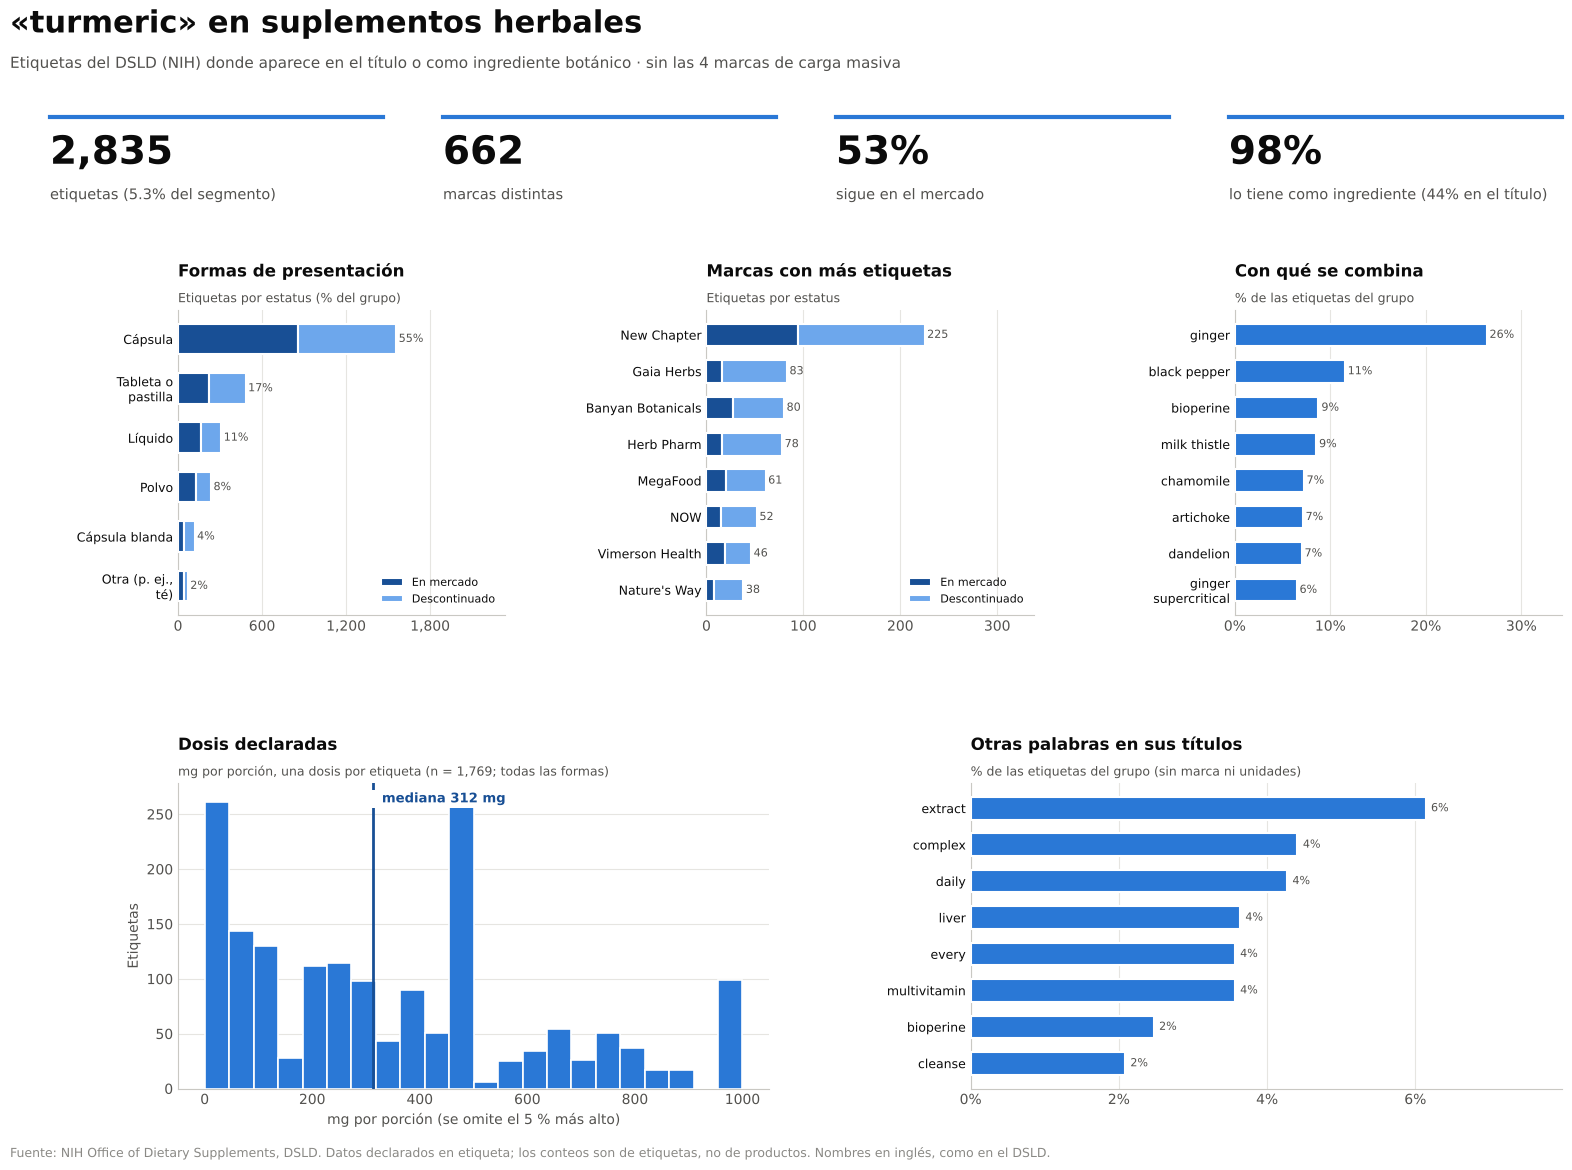

,Producto,Marca,Forma,Estatus,Año de entrada
0,Curcumin 95 500 mg,21st Century,Cápsula,On Market,2019
1,Turmeric Complex 500 mg,21st Century,Cápsula,On Market,2020
2,Turmeric Complex 500 mg,21st Century,Cápsula,On Market,2022
3,MusculoSkeletal Formula,4Life Fundamentals,Cápsula,On Market,2023
4,Wood Tonify Tonify Blood,5 Chinese Elements,Cápsula,On Market,2013
5,Pump with S7,5% Core,Cápsula,On Market,2025
6,Boswellin & Curcumin C3 Complex,AFI America's Finest,"Otra (p. ej., té)",On Market,2017
7,Boswellin & Curcuminoids,AFI America's Finest,Tableta o pastilla,Off Market,2011
8,Curcumin C3 Complex W/BioPerine,AFI America's Finest,"Otra (p. ej., té)",On Market,2017
9,Curcumin C3 Power Chewable,AFI America's Finest,Tableta o pastilla,On Market,2021


In [5]:
dashboard("turmeric")

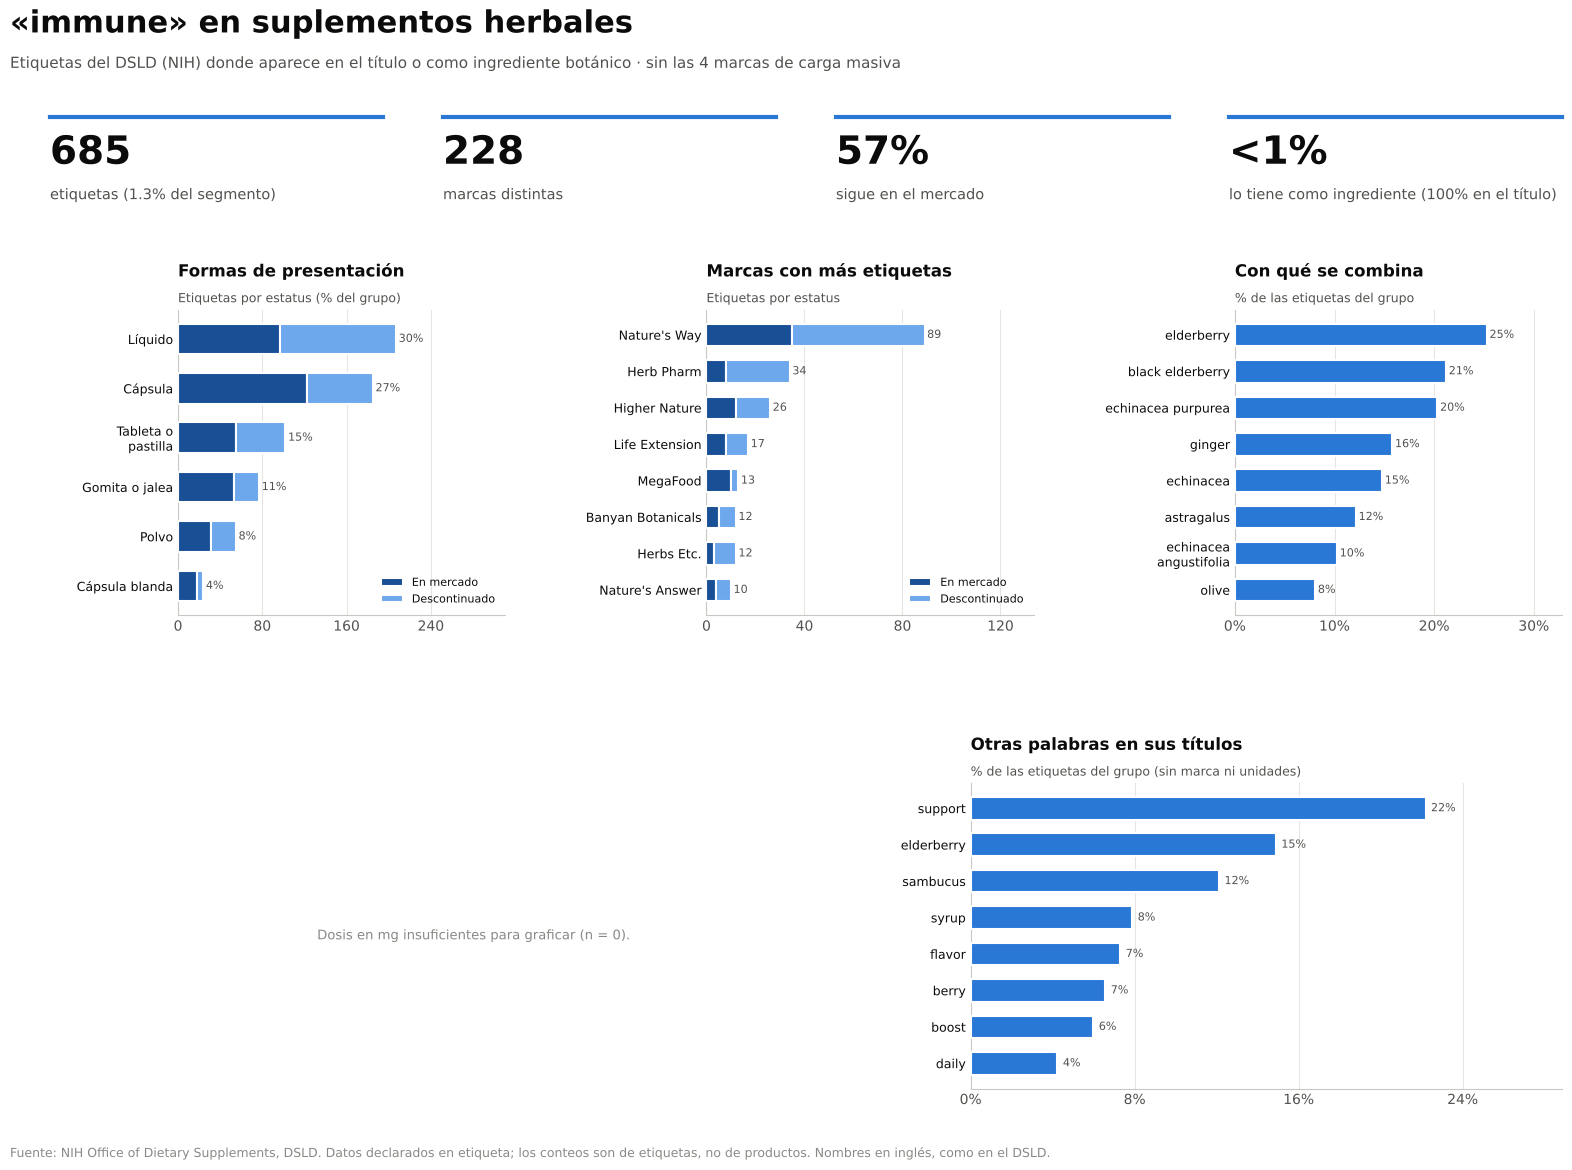

,Producto,Marca,Forma,Estatus,Año de entrada
0,Immune Support Plus Multivitamin,Airborne Everyday,Tableta o pastilla,On Market,2017
1,Immune - Assist Daily Formula,Aloha Medicinals,Cápsula,On Market,2023
2,Immune Assist Complete,Aloha Medicinals,Cápsula,On Market,2020
3,Immune-Assist Critical Care Formula 600 mg,Aloha Medicinals,Cápsula,On Market,2020
4,Immune-Assist Daily Formula 500 mg,Aloha Medicinals,Cápsula,Off Market,2014
5,Enhanced Immune Support,Alpine Nutrition,Cápsula,On Market,2021
6,Black Seed Gold Immune Support,Amazing Herbs,Cápsula,Off Market,2015
7,Immune Support,Amvilab,Cápsula,On Market,2023
8,Multi Mushroom Daily Immune Defense,Ancient Nutrition,Tableta o pastilla,Off Market,2022
9,Immune Booster +BioPerine,Approved Science,Cápsula,On Market,2024


In [6]:
dashboard("immune", donde="titulo")

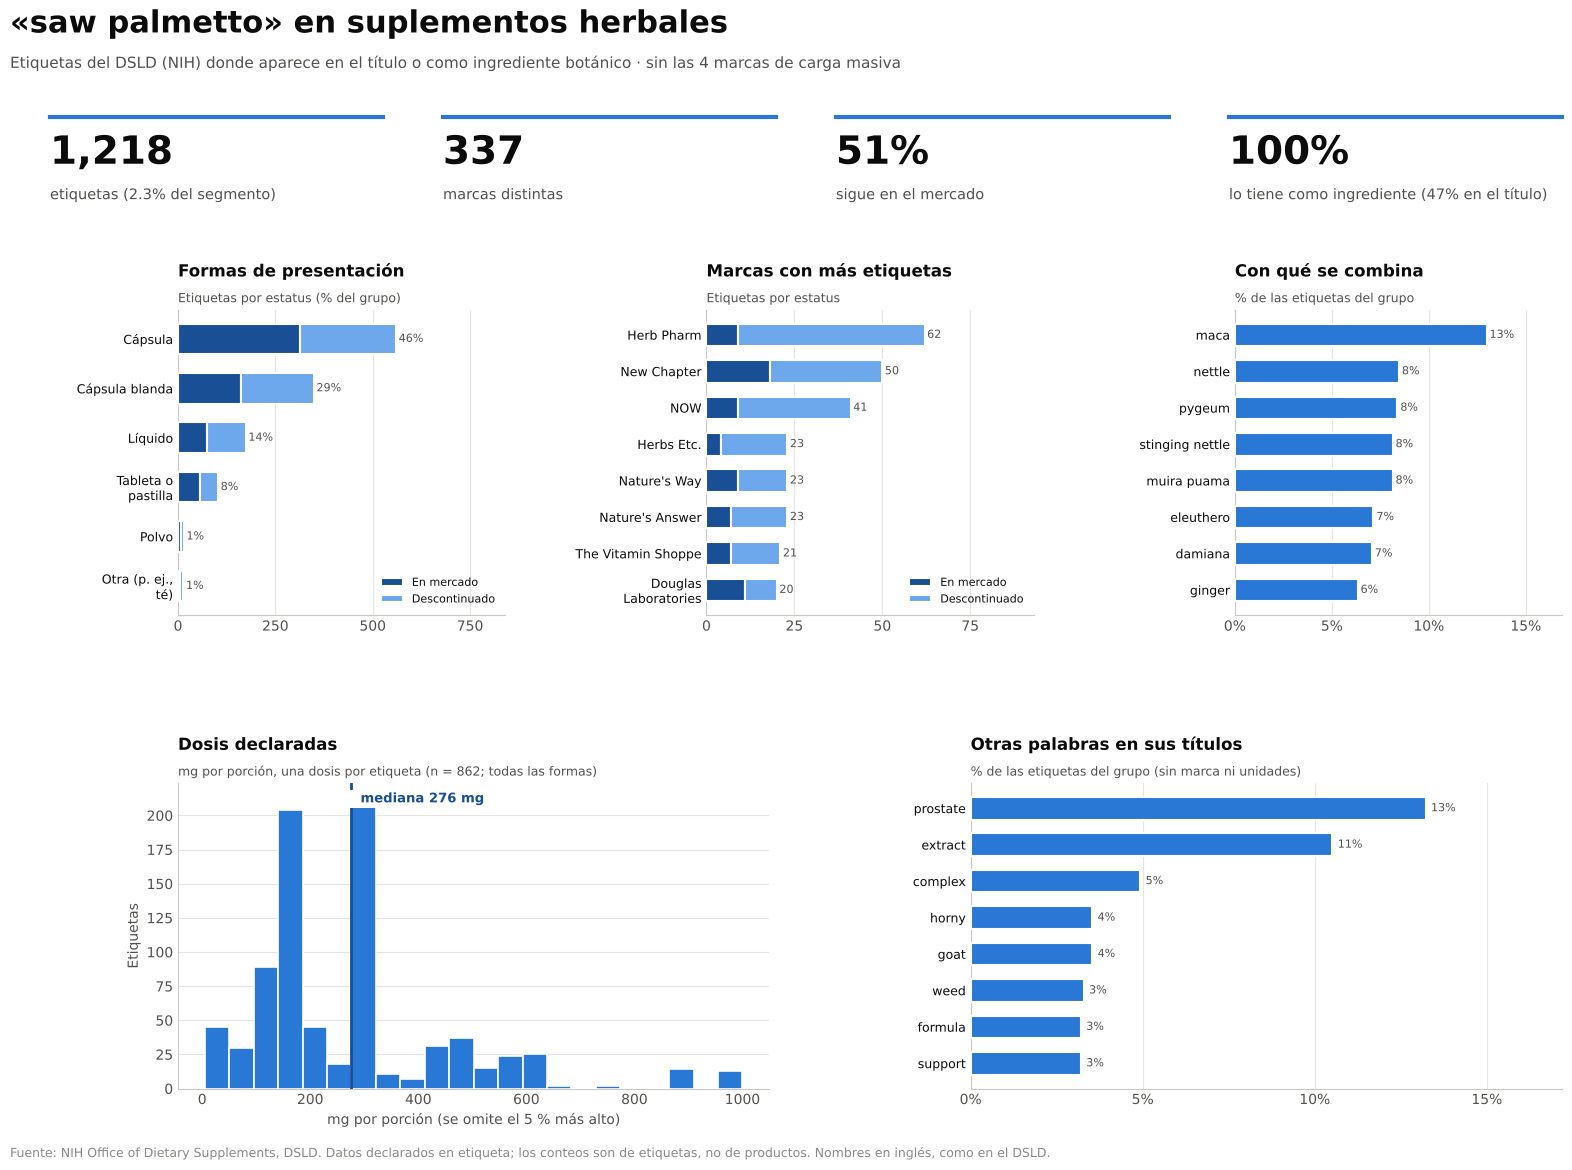

,Producto,Marca,Forma,Estatus,Año de entrada
0,Saw Palmetto 450 mg,21st Century,Cápsula,Off Market,2019
1,Saw Palmetto 450 mg,21st Century,Cápsula,Off Market,2019
2,Saw Palmetto 450 mg,21st Century,Cápsula,On Market,2021
3,Saw Palmetto 450 mg,21st Century,Cápsula,On Market,2021
4,Saw Palmetto Extract,21st Century,Cápsula,Off Market,2012
5,Saw Palmetto Extract,21st Century,Cápsula,Off Market,2015
6,Standardized Saw Palmetto Extract,21st Century,Cápsula,Off Market,2012
7,Standardized Saw Palmetto Extract,21st Century,Cápsula,Off Market,2015
8,Standardized Saw Palmetto Extract,21st Century,Cápsula,Off Market,2015
9,MusculoSkeletal Formula,4Life Fundamentals,Cápsula,On Market,2023


In [7]:
dashboard("saw palmetto")

## 5. Busca lo que quieras

Escribe un término y pulsa **Generar dashboard** (o Enter). Si la caja no aparece, llama a la función directamente: `dashboard("ginger")`.

In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output, display

    caja = widgets.Text(value="ashwagandha", description="Buscar:", layout=widgets.Layout(width="320px"))
    donde = widgets.Dropdown(options=[("Título o ingrediente", "ambos"), ("Solo ingrediente", "ingrediente"),
                                      ("Solo título", "titulo")], layout=widgets.Layout(width="200px"))
    boton = widgets.Button(description="Generar dashboard", button_style="primary")
    salida = widgets.Output()

    def al_pulsar(_):
        with salida:
            clear_output(wait=True)
            dashboard(caja.value, donde.value)

    boton.on_click(al_pulsar)
    caja.on_submit(al_pulsar)
    display(widgets.HBox([caja, donde, boton]), salida)
except ImportError:
    print('ipywidgets no está disponible: usa dashboard("ginger") en una celda.')

/tmp/ipykernel_702/982103243.py:17: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  caja.on_submit(al_pulsar)


Output()

## Limitaciones
- La búsqueda es por **palabra completa** y en inglés; no entiende sinónimos (*sambucus* y *elderberry* son búsquedas distintas) ni errores de ortografía, aunque sugiere nombres parecidos cuando no hay resultados.
- Los ingredientes se buscan sobre nombres **limpiados** (sin *extract*, *root*, *organic*…), así que `turmeric root extract` cuenta como `turmeric`.
- Las dosis son lo declarado por **porción**, mezclando todas las formas.
- Los conteos son de **etiquetas**, no de productos distintos; una misma presentación puede tener varias etiquetas.
- Hay productos que solo mencionan el término en el título y no lo tienen como ingrediente (y al revés); el KPI de la derecha lo muestra.